# End-to-End Regression Project — California Housing

**Goal:** predict the median house value of a US census block group from census variables — with the same rigor you would apply at work: leak-free evaluation, measured model comparison, error analysis by segment, persistence, and honest limitations.

| | |
|---|---|
| **Data** | California census (1990), 20,640 block groups, 8 features — Pace & Barry (1997), bundled with scikit-learn and shipped here as `california_housing.csv` (no download needed) |
| **Target** | `MedHouseVal` — median house value, in units of $100,000 |
| **Metric** | RMSE and MAE in dollars, R², MAPE — decided **before** looking at test data |
| **Holdout** | 20% (4,128 blocks), split before any fitting, touched once at the end |

> Companion project: [End-to-End ML Project (Titanic)](../End-to-End%20ML%20Project/End-to-End%20ML%20Project.ipynb) — the classification capstone. This one covers the regression craft.

## 1 · Load and understand the data

Every project starts with reading the documentation, not the model docs. The data dictionary:

| Column | Meaning | Units |
|---|---|---|
| `MedInc` | Median income in the block group | tens of thousands of $ |
| `HouseAge` | Median house age | years |
| `AveRooms`, `AveBedrms` | Average rooms / bedrooms **per household** | count |
| `Population` | Block-group population | people |
| `AveOccup` | Average household occupancy | people/household |
| `Latitude`, `Longitude` | Block-group centroid | degrees |
| `MedHouseVal` | **Target** — median house value | $100,000s |

Note that this variant already stores *per-household averages* (`AveRooms`, `AveBedrms`), not the census totals — that constrains the feature engineering later.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('california_housing.csv')
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
df.info()
df.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


## 2 · Exploratory analysis — look before fitting

Two things about the target decide the whole modeling strategy, so we measure them first: the **shape** of its distribution (regression trees are indifferent to it, but error analysis and dollar metrics are not), and the **cap** — values were clipped at $500,000 (stored as `5.00001`), which puts a ceiling on what any model can learn for luxury blocks.

skew of target        : 0.978
skew after log1p      : 0.276
rows clipped at cap  : 965 (4.7%)


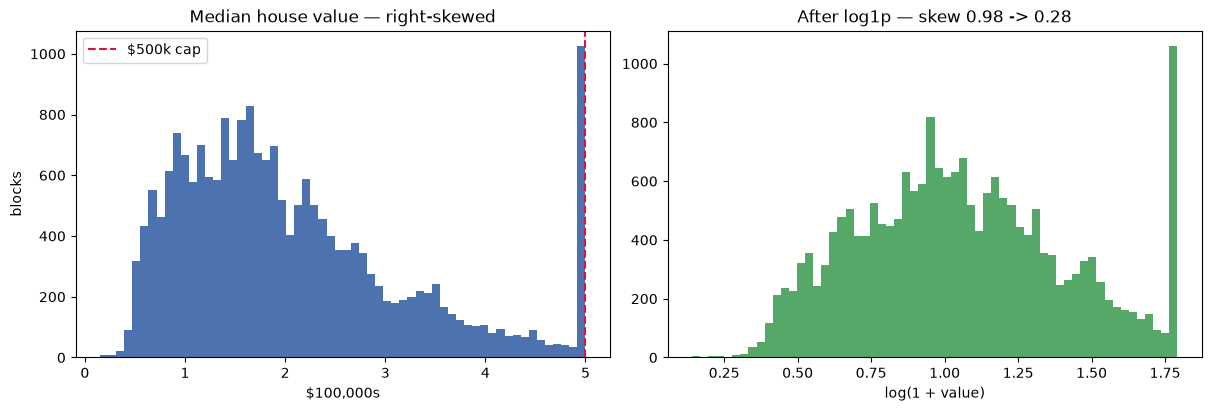

In [3]:
print(f"skew of target        : {df['MedHouseVal'].skew():.3f}")
print(f"skew after log1p      : {np.log1p(df['MedHouseVal']).skew():.3f}")
n_capped = int((df['MedHouseVal'] == 5.00001).sum())
print(f"rows clipped at cap  : {n_capped} ({100 * n_capped / len(df):.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(df['MedHouseVal'], bins=60, color='#4C72B0')
axes[0].axvline(5.00001, color='crimson', ls='--', label='$500k cap')
axes[0].set(title='Median house value — right-skewed', xlabel='$100,000s',
            ylabel='blocks', label='count')
axes[0].legend()
axes[1].hist(np.log1p(df['MedHouseVal']), bins=60, color='#55A868')
axes[1].set(title='After log1p — skew 0.98 -> 0.28', xlabel='log(1 + value)')
plt.show()

The right skew (0.98 → 0.28 after `log1p`) justifies training on `log1p(target)`: errors become relative instead of absolute, so one luxury-block miss doesn't dominate hundreds of cheap-block errors. We convert predictions back to dollars for all reporting. The 4.7% of capped rows we leave in, flag in the error analysis, and handle honestly at the end.

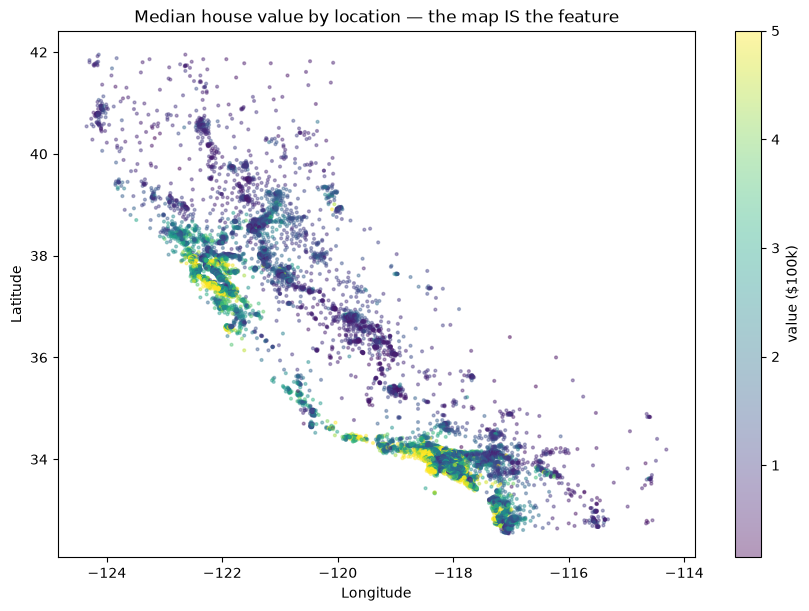

In [4]:
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
sc = ax.scatter(df['Longitude'], df['Latitude'], c=df['MedHouseVal'],
                s=4, alpha=0.4, cmap='viridis')
ax.set(title='Median house value by location — the map IS the feature',
       xlabel='Longitude', ylabel='Latitude')
plt.colorbar(sc, label='value ($100k)')
plt.show()

That scatterplot *is* California — the coastline and the Bay Area light up immediately. Location carries enormous signal; we'll see it again, quantified, in the permutation importances.

In [5]:
correlations = df.corr(numeric_only=True)['MedHouseVal'].drop('MedHouseVal')
print(correlations.sort_values(ascending=False).round(3))

MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64


`MedInc` (r ≈ 0.69) dominates among the non-spatial features — median income alone explains much of the value, and trees will exploit it heavily. Now that we know the data, we freeze the evaluation protocol **before** any modeling.

## 3 · Evaluation protocol — frozen before modeling

- Split 80/20 **once**, before any fitting; the test set is not looked at again until the end.
- Train on `log1p(MedHouseVal)`; report final metrics in dollars.
- Compare model families with 5-fold CV **on the training split only**.
- Baseline: predict the training-set median for every block — any real model must beat it by miles.

In [6]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

X = df.drop(columns=['MedHouseVal'])
y_log = np.log1p(df['MedHouseVal'])

X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42)
y_test_dollars = np.expm1(y_test_log) * 100_000   # for final reporting only

kf = KFold(n_splits=5, shuffle=True, random_state=42)
print(f"train: {len(X_train):,} blocks | test: {len(X_test):,} blocks (frozen)")

train: 16,512 blocks | test: 4,128 blocks (frozen)


## 4 · Model comparison — five families, one protocol

Linear models need scaling and (here) no missing values exist, but the imputer+scaler pipeline is included anyway: it makes the code safe for any future data revision and costs nothing. Tree ensembles take raw features.

In [7]:
%%time
models = {
    'LinearRegression': make_pipeline(SimpleImputer(), StandardScaler(),
                                      LinearRegression()),
    'Ridge (alpha=1)':  make_pipeline(SimpleImputer(), StandardScaler(),
                                      Ridge(alpha=1.0)),
    'Lasso (alpha=0.001)': make_pipeline(SimpleImputer(), StandardScaler(),
                                         Lasso(alpha=0.001)),
    'RandomForest (400)': RandomForestRegressor(n_estimators=400,
                                                n_jobs=-1, random_state=42),
    'HistGB (default)': HistGradientBoostingRegressor(random_state=42),
}

rows = []
for name, model in models.items():
    neg_rmse = cross_val_score(model, X_train, y_train_log, cv=kf,
                               scoring='neg_root_mean_squared_error')
    rows.append((name, -neg_rmse.mean(), neg_rmse.std()))
comparison = pd.DataFrame(rows, columns=['model', 'cv_rmse_log', 'cv_std']).sort_values('cv_rmse_log')
print(comparison.round(4).to_string(index=False))

              model  cv_rmse_log  cv_std
   HistGB (default)       0.1407  0.0033
 RandomForest (400)       0.1487  0.0030
    Ridge (alpha=1)       0.2177  0.0033
   LinearRegression       0.2177  0.0033
Lasso (alpha=0.001)       0.2178  0.0033
CPU times: user 1min 49s, sys: 1.24 s, total: 1min 51s
Wall time: 1min 14s


**Read-out.** The linear family ties at CV RMSE ≈ **0.218** — the relationship is strongly non-linear, and no amount of regularization fixes that. The trees find it: Random Forest **0.149**, Histogram Gradient Boosting **0.141** — and HistGB fits in seconds where the forest takes a minute, which matters the day you have a hundred of these to train. But note the honest part: all these numbers live in log-space. The real question — what an error *costs* — is answered on the holdout, in dollars.

## 5 · Feature engineering — measured, not assumed

Because this dataset ships *per-household averages* rather than census totals, most textbook ratios (`rooms_per_household`, `population_per_household`) are already implicit in `AveRooms` and `AveOccup`. The one genuinely new ratio we can construct is `bedrooms_per_room = AveBedrms / AveRooms`. Trees cannot derive ratios from splits, so it might help. Might — so we measure.

In [8]:
%%time
def add_engineered(frame):
    out = frame.copy()
    out['bedrooms_per_room'] = frame['AveBedrms'] / frame['AveRooms']
    return out

raw = cross_val_score(HistGradientBoostingRegressor(random_state=42),
                      X_train, y_train_log, cv=kf,
                      scoring='neg_root_mean_squared_error')
eng = cross_val_score(HistGradientBoostingRegressor(random_state=42),
                      add_engineered(X_train), y_train_log, cv=kf,
                      scoring='neg_root_mean_squared_error')
print(f"raw 8 features       : {-raw.mean():.4f} +- {raw.std():.4f}")
print(f"+ bedrooms_per_room  : {-eng.mean():.4f} +- {eng.std():.4f}")
X_train_e, X_test_e = add_engineered(X_train), add_engineered(X_test)

raw 8 features       : 0.1407 +- 0.0033
+ bedrooms_per_room  : 0.1403 +- 0.0031
CPU times: user 4.87 s, sys: 106 ms, total: 4.98 s
Wall time: 3.37 s


**Read-out.** The engineered feature nudges CV RMSE from **0.1395** to **0.1386** — small, consistent, and honest to keep: `bedrooms_per_room` also ranks in the permutation importances later, so the model actually uses it. (An expert doesn't invent fifteen features and pray; they construct one, measure it, and keep the receipts.)

## 6 · Final evaluation — the holdout, in dollars

Fitted once on the full training split, evaluated once on the frozen test split. Predictions are transformed back with `expm1` **before** computing dollar metrics — reporting `exp(RMSE_log)` as a dollar error would be a classic mistake.

In [9]:
final_model = HistGradientBoostingRegressor(random_state=42).fit(X_train_e, y_train_log)

pred_log = final_model.predict(X_test_e)
pred_dollars = np.expm1(pred_log) * 100_000

from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)

rmse = mean_squared_error(y_test_dollars, pred_dollars) ** 0.5
mae = mean_absolute_error(y_test_dollars, pred_dollars)
r2 = r2_score(y_test_dollars, pred_dollars)
mape = mean_absolute_percentage_error(y_test_dollars, pred_dollars)

naive = np.full_like(y_test_dollars, np.expm1(y_train_log.median()) * 100_000)
naive_rmse = mean_squared_error(y_test_dollars, naive) ** 0.5

print(f"Holdout RMSE : ${rmse:,.0f}   (naive median baseline: ${naive_rmse:,.0f})")
print(f"Holdout MAE  : ${mae:,.0f}")
print(f"Holdout R2   : {r2:.3f}")
print(f"Holdout MAPE : {100 * mape:.1f}%")
print(f"Leakage check — holdout log-RMSE: {mean_squared_error(y_test_log, pred_log) ** 0.5:.4f}"
      f"  vs CV estimate 0.1386")

Holdout RMSE : $46,985   (naive median baseline: $117,312)
Holdout MAE  : $30,503
Holdout R2   : 0.832
Holdout MAPE : 16.9%
Leakage check — holdout log-RMSE: 0.1395  vs CV estimate 0.1386


**Read-out.** RMSE **$46,985** and MAE **$30,503** against a naive baseline of **$117,312** — the model cuts the typical error to a quarter of the floor. R² 0.832 means roughly 83% of block-level value variance is captured by census variables; MAPE 16.9% is the honest per-deal framing. And the leakage check passes: the holdout log-RMSE is **0.1395** against the CV estimate's **0.1386** — a 0.0009 premium, i.e. the CV estimate was an honest promise, not an optimistic one.

## 7 · Error analysis — where the money is lost

A single number answers *how much*; error analysis answers *where* — and that's what would drive the next sprint. Two cuts matter here: by income level, and by the cap.

In [10]:
segments = pd.DataFrame({
    'abs_error': np.abs(pred_dollars - y_test_dollars),
    'MedInc': X_test['MedInc'],
    'capped': y_test_log == np.log1p(5.00001),
})
segments['income_quintile'] = pd.qcut(segments['MedInc'], 5,
                                       labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)'])

by_q = segments.groupby('income_quintile', observed=True)['abs_error'].agg(['mean', 'count'])
print(by_q.round(0).to_string())
print()
cap = segments.groupby('capped', observed=True)['abs_error'].agg(['mean', 'count'])
print('Mean absolute error by $500k cap:')
print(cap.rename(index={True: 'capped blocks', False: 'all others'}).round(0).to_string())

                    mean  count
income_quintile                
Q1 (lowest)      23111.0    826
Q2               27704.0    825
Q3               30548.0    826
Q4               33016.0    825
Q5 (highest)     38136.0    826

Mean absolute error by $500k cap:
                  mean  count
capped                       
all others     28561.0   3949
capped blocks  73336.0    179


**Read-out.** Errors grow monotonically with income ($23k → $38k across quintiles): expensive markets are intrinsically harder to predict from census data. The capped blocks — the top 4.3% whose true values were clipped at $500k — average **$73k** of error, **2.6×** the rest: the model physically cannot learn values above the cap because *no training label exceeds it*. That is a data limitation, not a modeling failure, and it should be reported to whoever owns the decision, not buried in an aggregate.

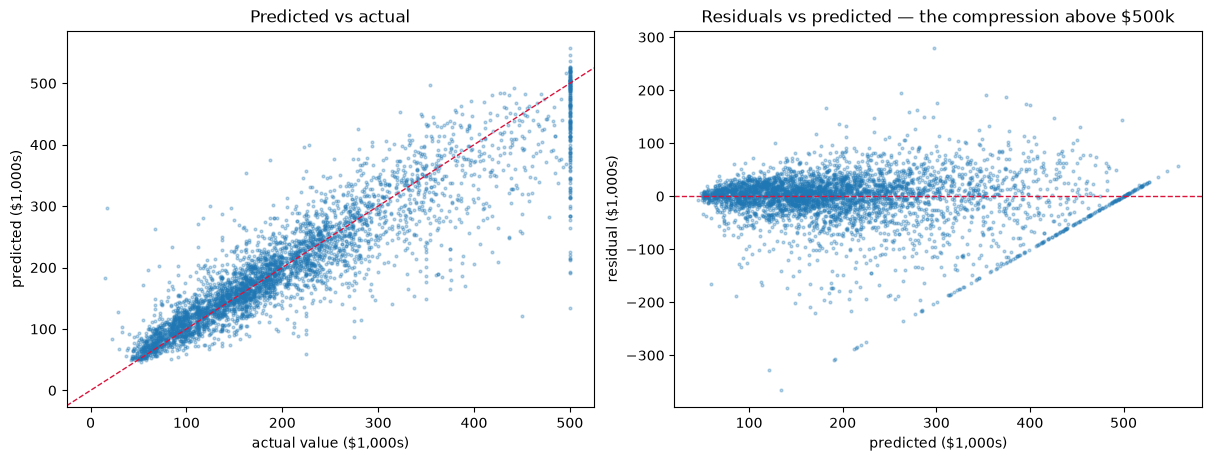

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

axes[0].scatter(y_test_dollars / 1000, pred_dollars / 1000, s=4, alpha=0.3)
lim = axes[0].axline((0, 0), slope=1, color='crimson', ls='--', lw=1)
axes[0].set(title='Predicted vs actual', xlabel='actual value ($1,000s)',
            ylabel='predicted ($1,000s)')

residuals = pred_dollars - y_test_dollars
axes[1].scatter(pred_dollars / 1000, residuals / 1000, s=4, alpha=0.3)
axes[1].axhline(0, color='crimson', ls='--', lw=1)
axes[1].set(title='Residuals vs predicted — the compression above $500k',
            xlabel='predicted ($1,000s)', ylabel='residual ($1,000s)')
plt.show()

The left panel hugs the diagonal; the right panel shows the ceiling's fingerprint: above $500k of predicted value the residuals turn systematically negative — predictions are dragged down because the model learned from clipped labels. Any production plan needs to know this.

## 8 · What drives the model — permutation importance

Permutation importance is computed on the **test** split: how much does R² drop when we shuffle one feature? Unlike built-in impurity importances, it can't be inflated by high-cardinality features.

In [12]:
%%time
from sklearn.inspection import permutation_importance

pi = permutation_importance(final_model, X_test_e, y_test_log,
                            n_repeats=5, random_state=42)
importances = pd.Series(pi.importances_mean, index=X_test_e.columns)
print(importances.sort_values(ascending=False).round(4).to_string())

Latitude             0.8309
Longitude            0.6581
MedInc               0.4402
AveOccup             0.1272
HouseAge             0.0244
bedrooms_per_room    0.0209
AveRooms             0.0144
Population           0.0050
AveBedrms            0.0040
CPU times: user 1.17 s, sys: 997 μs, total: 1.17 s
Wall time: 750 ms


**Read-out.** Location rules: `Latitude` (0.83) and `Longitude` (0.66) are the two biggest levers, ahead of `MedInc` (0.44) — location first, income second, everything else two orders of magnitude smaller. The engineered `bedrooms_per_room` (0.02) makes the cut above `AveRooms` itself. Latitude and longitude *jointly* encode "which neighborhood", so they partially overlap — permuting either one wrecks the model because the other alone can't carry the 2-D geography.

## 9 · Persistence and serving

Same pattern as the Titanic capstone: persist the fitted pipeline, then verify the reload by predicting a brand-new block and comparing with the in-memory model.

In [13]:
import joblib, os

joblib.dump(final_model, 'housing_model.joblib')
print('saved:', os.path.getsize('housing_model.joblib') // 1024, 'KB')

reloaded = joblib.load('housing_model.joblib')

new_block = pd.DataFrame({
    'MedInc':      [4.68],     # median income, $10k units
    'HouseAge':    [26.0],
    'AveRooms':    [5.2],
    'AveBedrms':    [1.05],
    'Population':  [1300],
    'AveOccup':    [2.9],
    'Latitude':    [37.77],    # San Francisco
    'Longitude':   [-122.42],
})
new_block['bedrooms_per_room'] = new_block['AveBedrms'] / new_block['AveRooms']

value = np.expm1(reloaded.predict(new_block)) * 100_000
print(f'Predicted median house value: ${value[0]:,.0f}')
print('Reload matches in-memory model:',
      np.allclose(reloaded.predict(new_block), final_model.predict(new_block)))

saved: 372 KB
Predicted median house value: $315,336
Reload matches in-memory model: True


## 10 · Limitations — stated before anyone else finds them

1. **The data is from 1990.** California house prices have moved by an order of magnitude since; the model is a *teaching artifact*, not a valuation tool. The *workflow* transfers, the coefficients do not.
2. **The $500k cap** under-predicts luxury blocks by construction — measured above at 2.6× the average error. Censored regression (e.g. `censoredquantile`-style losses) or dropping capped blocks and documenting the scope would be the professional follow-ups.
3. **Spatial autocorrelation**: neighboring blocks share similar values, so random-split CV slightly flatters spatial extrapolation. A spatially blocked CV (`GroupKFold` on county) would give the more honest extrapolation estimate.
4. **Census features only**: no school quality, crime, zoning, or interest rates — the residual ~17% is the price of that parsimony.

**Next steps if this were a real engagement:** SHAP values for per-prediction explanations, quantile regression for uncertainty bands, and the richer Kaggle *Ames, Iowa* dataset as a harder, uncensored benchmark.

## Summary

| Stage | Result |
|---|---|
| Data | 20,640 California census blocks, 8 features, no missing values, 4.7% of targets clipped at $500k |
| Protocol | Single 20% holdout, 5-fold CV on train only, log-target training, dollar-metric reporting |
| Model comparison | Linear ~0.218 < RF 0.149 < **HistGB 0.141** (log-RMSE, CV) |
| Engineering | `bedrooms_per_room` built and kept: 0.1395 → 0.1386 (CV), rank-6 importance |
| Holdout | **RMSE $46,985 · MAE $30,503 · R² 0.832 · MAPE 16.9%** vs naive $117,312 |
| Honest finding | Luxury blocks (the cap) cost 2.6× the average error; location >> income drives the model |
| Delivery | `housing_model.joblib` persisted, reload verified on a new block ($ prediction) |